# ***Celda 1: Instalación de librerías***

In [1]:
!pip -q install geopy unidecode trafilatura requests-cache feedparser umap-learn folium

# ***Celda 2: Configuración General***

In [2]:
import re, os, time, json, random, shutil, urllib.robotparser
from urllib.parse import urlparse, urljoin
import requests, requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
import pandas as pd, numpy as np
from unidecode import unidecode
import trafilatura

CONTACTO = "tu_correo@umsa.edu.bo"   # <-- CAMBIA ESTO
USER_AGENT = f"ProyectoUniversitarioML/2.0 (investigacion academica; contacto: {CONTACTO})"
PAUSA_MIN, PAUSA_MAX = 3.0, 6.0      # segundos entre peticiones REALES (las de caché no esperan)
MAX_ERRORES_SEGUIDOS = 3             # 403/429 seguidos -> el cliente se detiene
CSV_EVENTOS = "eventos_bolivia.csv"  # archivo nacional para toda Bolivia
CSV_ANTERIOR = "eventos_lapaz_v3.csv" # si existe de tu corrida previa, se migra automáticamente
CACHE_GEO = "cache_geocoder.json"

# **Celda 3: Diccionario de Zonas de Bolivia (La Paz, El Alto, Santa Cruz, Cochabamba y país)**

In [3]:
import re

# Diccionario organizado de zonas, barrios y arterias neurálgicas de Bolivia
PATRONES_ZONAS = {
    # --- MACRODISTRITO CENTRO (LA PAZ) ---
    "Pérez Velasco": ["perez velasco", "pérez velasco", "plaza perez", "pasarela perez"],
    "San Francisco": ["san francisco", "plaza san francisco", "sagarnaga", "calle sagárnaga"],
    "Plaza Murillo": ["plaza murillo", "calle comercio", "calle ingavi", "calle socabaya", "calle ballivian", "calle indaburo", "indaburo"],
    "El Prado": ["el prado", "paseo del prado", "avenida 16 de julio", "plaza del estudiante"],
    "San Pedro": ["san pedro", "plaza sucre", "plaza san pedro", "calle colombia", "panóptico de san pedro", "alto san pedro"],
    "Camacho": ["avenida camacho", "mercado camacho", "calle bueno", "santa barbara"],
    "Miraflores": ["miraflores", "plaza villarroel", "estadio hernando siles", "avenida saavedra",
                   "plaza triangular", "hospital de clinicas", "avenida brasil", "puente de las americas"],
    "San Jorge": ["san jorge", "avenida arce", "plaza el condor"],

    # --- MACRODISTRITO COTAHUMA (LA PAZ) ---
    "Sopocachi": ["sopocachi", "plaza abaroa", "plaza españa", "calle 20 de octubre",
                  "avenida 6 de agosto", "belisario salinas", "plaza monticulo", "montículo"],
    "Tembladerani": ["tembladerani", "cancha de tembladerani", "jaimes freyre"],
    "Bajo Llojeta": ["bajo llojeta", "llojeta", "mario mercado"],
    "Pasankeri": ["pasankeri", "curva de holguin"],
    "Tacagua": ["tacagua", "faro murillo"],
    "Alpacoma": ["alpacoma", "relleno sanitario alpacoma"],

    # --- MACRODISTRITO MAX PAREDES (LA PAZ) ---
    "Garita de Lima": ["garita de lima", "plaza garita de lima", "calle tumusla", "tumusla"],
    "Gran Poder": ["gran poder", "calle illampu", "calle vicente ochoa", "calle gallardo", "eloy salmon", "calle eloy salmon"],
    "Avenida Buenos Aires": ["avenida buenos aires", "av. buenos aires", "buenos aires y max paredes"],
    "El Tejar": ["el tejar", "calle collasuyo", "cementerio general"],
    "Villa Victoria": ["villa victoria", "plaza huallparrimachi"],
    "Chijini": ["chijini", "plaza marcelo quiroga santa cruz"],
    "Munaypata": ["munaypata", "autopista la paz el alto", "puente autopista"],
    "Pura Pura": ["pura pura", "bosquecillo de pura pura"],

    # --- MACRODISTRITO PERIFÉRICA (LA PAZ) ---
    "Villa Fátima": ["villa fátima", "villa fatima", "plaza del maestro", "mercado villa fatima", "terminal minasa"],
    "Achachicala": ["achachicala", "carril de subida", "avenida ramiro castillo"],
    "Vino Tinto": ["vino tinto", "puente minasa"],
    "Rosasani": ["rosasani", "plaza de rosasani"],

    # --- MACRODISTRITO SAN ANTONIO (LA PAZ) ---
    "Villa Copacabana": ["villa copacabana", "hospital san gabriel", "avenida circunvalacion"],
    "Villa San Antonio": ["villa san antonio", "san antonio alto", "san antonio bajo", "plaza libertad"],
    "Pampahasi": ["pampahasi", "alto pampahasi", "bajo pampahasi"],
    "Kupini": ["kupini", "callapa"],

    # --- MACRODISTRITO SUR Y MALLASA (LA PAZ) ---
    "Obrajes": ["obrajes", "calle 17 de obrajes", "calle 8 de obrajes", "calle 2 de obrajes", "avenida hernando siles"],
    "Bella Vista": ["bella vista", "plaza de bella vista"],
    "Següencoma": ["seguencoma", "següencoma", "bajo següencoma"],
    "Calacoto": ["calacoto", "calle 21 de calacoto", "calle 8 de calacoto", "plaza humboldt", "avenida ballivian"],
    "San Miguel": ["san miguel", "avenida montenegro", "calle pancara"],
    "La Florida": ["la florida", "puente amor de dios"],
    "Los Pinos": ["los pinos", "plaza los pinos"],
    "Cota Cota": ["cota cota", "calle 28 de cota cota", "campus cota cota", "laguna de cota cota"],
    "Chasquipampa": ["chasquipampa", "calle 50 de chasquipampa", "calle 42 de chasquipampa"],
    "Achumani": ["achumani", "calle 22 de achumani", "avenida garcia lanza", "complejo the strongest"],
    "Irpavi": ["irpavi", "irpavi 2", "megacenter", "avenida ovando"],
    "Mallasa": ["mallasa", "valle de la luna"],

    # --- CIUDAD DE EL ALTO ---
    "La Ceja": ["la ceja", "ceja de el alto", "ceja el alto", "calle 1 de la ceja", "pasarela del arquitecto", "avenida 6 de marzo"],
    "Villa Dolores": ["villa dolores", "plaza juana azurduy"],
    "12 de Octubre": ["zona 12 de octubre", "urbanizacion 12 de octubre", "calle jorge carrasco", "calle raul salmon"],
    "Ciudad Satélite": ["ciudad satelite", "ciudad satélite", "plaza del obelisco el alto"],
    "Río Seco": ["rio seco", "río seco", "ex tranca rio seco", "puente rio seco", "huayna potosi"],
    "Senkata": ["senkata", "ex tranca senkata", "planta de senkata"],
    "Ballivián": ["ballivian el alto", "plaza ballivian", "plaza ballivián"],
    "Cruce Villa Adela": ["cruce villa adela", "villa adela", "romero pampa"],
    "Villa Esperanza": ["villa esperanza", "upea"],

    # --- TERMINALES E HITOS LA PAZ / EL ALTO ---
    "Terminal de Buses La Paz": ["terminal de buses", "terminal de la paz", "plaza antogafasta"],
    "Terminal Minasa": ["terminal minasa"],
    "Terminal Interprovincial": ["terminal interprovincial de el alto"],
    "Tranca de Urujara": ["urujara", "tranca de urujara"],

    # --- SANTA CRUZ DE LA SIERRA Y METRÓPOLI ---
    "Plan 3000": ["plan 3000", "plan tres mil", "ciudadela andres ibanez"],
    "Villa 1 de Mayo": ["villa 1 de mayo", "villa primero de mayo"],
    "La Ramada": ["la ramada", "mercado la ramada", "nuevo mercado la ramada"],
    "Los Pozos": ["los pozos", "mercado los pozos"],
    "Mutualista": ["mercado mutualista", "avenida mutualista"],
    "Equipetrol": ["equipetrol", "cordon ecologico", "cordón ecológico", "cuarto anillo", "4to anillo"],
    "Pampa de la Isla": ["pampa de la isla", "virgen de lujan"],
    "Los Lotes": ["los lotes", "zona los lotes"],
    "Urubó": ["urubo", "urubó", "porongo"],
    "Terminal Bimodal": ["terminal bimodal"],

    # --- COCHABAMBA Y METRÓPOLI ---
    "La Cancha": ["la cancha", "mercado la pampa", "mercado calatayud", "avenida aroma", "san antonio cochabamba"],
    "Cala Cala": ["cala cala", "plaza las banderas", "el prado cochabamba"],
    "Zona Sur Cochabamba": ["jaihuayco", "k'ara k'ara", "kara kara", "valle hermoso cochabamba", "alalay"]
}

# Mapa de pertenencia de cada zona a su ciudad/departamento para geocodificar sin ambigüedad
ZONA_A_CIUDAD = {}
for _z in ["La Ceja", "Villa Dolores", "12 de Octubre", "Ciudad Satélite", "Río Seco", "Senkata", "Ballivián", "Cruce Villa Adela", "Villa Esperanza", "Terminal Interprovincial"]:
    ZONA_A_CIUDAD[_z] = "El Alto"
for _z in ["Plan 3000", "Villa 1 de Mayo", "La Ramada", "Los Pozos", "Mutualista", "Equipetrol", "Pampa de la Isla", "Los Lotes", "Urubó", "Terminal Bimodal"]:
    ZONA_A_CIUDAD[_z] = "Santa Cruz"
for _z in ["La Cancha", "Cala Cala", "Zona Sur Cochabamba"]:
    ZONA_A_CIUDAD[_z] = "Cochabamba"
for _z in PATRONES_ZONAS:
    ZONA_A_CIUDAD.setdefault(_z, "La Paz")

# **Celda 4: Clasificación Mejorada (Zonas, Delitos, Hora, Vías y Ciudades de Bolivia)**

In [4]:
def norm(t): return unidecode(t or "").lower()

# ---------- ZONAS ----------
def reconstruir_alias():
    """Recompila los alias de zonas (llámala después de agregar zonas nuevas)."""
    global _ALIAS_RE
    alias = sorted([(norm(a), z) for z, als in PATRONES_ZONAS.items() for a in als], key=lambda x: -len(x[0]))
    _ALIAS_RE = [(re.compile(rf"\b{re.escape(a)}\b"), z) for a, z in alias]
reconstruir_alias()

def detectar_zonas(texto):
    t = norm(texto); cnt, pos = {}, {}
    for rx, z in _ALIAS_RE:
        for m in rx.finditer(t):
            cnt[z] = cnt.get(z, 0) + 1
            pos.setdefault(z, m.start())
        t = rx.sub(lambda m: " " * len(m.group()), t)   # evita contar subcadenas
    return cnt, pos

def zona_principal(titulo, cuerpo):
    ct, _ = detectar_zonas(titulo)
    cb, pb = detectar_zonas(cuerpo)
    todas = list(dict.fromkeys(list(ct) + sorted(cb, key=pb.get)))
    if ct:
        return max(ct, key=lambda z: (ct[z], cb.get(z, 0))), todas
    if cb:
        return max(cb, key=lambda z: (cb[z], -pb[z])), todas
    return None, []

# ---------- DELITOS (raíces, sin tildes; \b al inicio, se admiten conjugaciones) ----------
DELITOS = {
 "Homicidio / Asesinato": [r"asesin", r"homicid", r"cadaver", r"sin vida", r"muerte violenta", r"feminicid", r"estrangul", r"ultimad", r"hallan muert", r"hallaron muert", r"acribill", r"sicari"],
 "Violencia sexual": [r"violacion", r"violaron", r"violador", r"abuso sexual", r"agresion sexual", r"estupro", r"tocamiento", r"infanticid"],
 "Agresión Física y Lesiones": [r"golpiza", r"agredi", r"agresion", r"herid", r"apunalad", r"acuchill", r"baleado", r"balazo", r"rina\b", r"pelea", r"lesion", r"linchamiento", r"atacaron", r"ataco"],
 "Robo Agravado / Asalto": [r"asalt", r"atraco", r"atracaron", r"atracad", r"cuchillo", r"arma de fuego", r"encanon", r"cogote", r"antisocial", r"secuestro\b", r"secuestrad[oa]", r"pistola", r"motoladron"],
 "Robo de Vehículos y Autopartes": [r"autoparte", r"retrovisor", r"robo de vehiculo", r"robo de auto", r"robo de movilidad", r"robo de motocicleta", r"placa clonada", r"desmantel", r"robaron su vehiculo"],
 "Hurto / Descuidismo": [r"hurt", r"sustrajo", r"bolsiqu", r"descuid", r"carterist", r"pildor", r"doparon", r"arrebat", r"ladron", r"robo\b", r"robos\b", r"robaron"],
 "Estafa y Engaño": [r"estaf", r"cuento del tio", r"falso policia", r"falsos policias", r"extorsi", r"librecambista", r"fraude", r"chantaje"],
 "Narcotráfico / Drogas": [r"droga", r"cocaina", r"marihuana", r"felcn", r"narcotrafic", r"estupefaciente", r"pasta base", r"narcot"],
}
ORDEN = list(DELITOS)   # prioridad: del más grave al menos grave
_DEL_RE = {c: re.compile(r"\b(?:" + "|".join(rs) + ")") for c, rs in DELITOS.items()}

_CONFLICTO = re.compile(r"\b(?:bloqueo|bloquean|bloqueadores|marcha|marchan|protesta|manifestant|paro\b|cerco|gasificacion|dinamita|movilizacion|vigilia)")
_JUDICIAL = re.compile(r"\b(?:exministro|exalcalde|expresidente|exjuez|exfiscal|exgobernador|detencion preventiva|detencion domiciliaria|malversacion|corrupcion|caso maletas|cibercrimen|audiencia cautelar)")

def clasificar_delitos(titulo, cuerpo):
    """Primero descarta lo que NO es delito callejero (conflicto social, noticias judiciales/políticas) mirando el título.
    Luego decide el delito con título + inicio de la nota (evita falsos positivos por menciones al final)."""
    tt = norm(titulo)
    if _CONFLICTO.search(tt): return "Conflicto social / Bloqueos", []
    if _JUDICIAL.search(tt) or re.match(r"caso\s", tt): return "Judicial / Político", []
    inicio = norm(titulo + ". " + cuerpo[:600]); todo = norm(titulo + ". " + cuerpo)
    principal = next((c for c in ORDEN if _DEL_RE[c].search(inicio)), None)
    todos = [c for c in ORDEN if _DEL_RE[c].search(todo)]
    if principal is None and todos: principal = todos[0]
    return (principal or "No especificado"), todos

# ---------- HORA ----------
def extraer_franja(texto):
    t = norm(texto)
    m = re.search(r"\ba las (\d{1,2})(?:[:\.h](\d{2}))?\s*(?:horas|hrs|h\b)?\s*(am|pm|de la manana|de la tarde|de la noche|de la madrugada)?", t)
    if m:
        h = int(m.group(1)); suf = m.group(3) or ""
        if h <= 23:
            if h < 12 and (suf in ("pm", "de la tarde", "de la noche")): h += 12
            return "Madrugada" if h < 6 else "Mañana" if h < 12 else "Tarde" if h < 19 else "Noche"
    if re.search(r"\bmadrugada\b", t): return "Madrugada"
    if re.search(r"\banoche\b|\bpor la noche\b|\besta noche\b|\bde noche\b", t): return "Noche"
    if re.search(r"\bpor la tarde\b|\besta tarde\b|\bde tarde\b", t): return "Tarde"
    if re.search(r"\bpor la manana\b|\besta manana\b|\ben la manana\b", t): return "Mañana"
    return "Desconocida"

# ---------- VÍA MENCIONADA (para geocodificación fina en la fase 2) ----------
_VIA = re.compile(r"\b(?:[Aa]v\.?|[Aa]venida|[Cc]alle|[Pp]asaje|[Pp]laza|[Pp]uente|[Aa]nillo)\s+[A-ZÁÉÍÓÚÑ0-9][\wÁÉÍÓÚÑáéíóúñ\.]*(?:\s+(?:de|del|la|el|los|las|y)?\s*[A-ZÁÉÍÓÚÑ0-9][\wÁÉÍÓÚÑáéíóúñ\.]*){0,3}")
def extraer_via(texto):
    m = _VIA.search(texto or "")
    return m.group(0).strip() if m else None

# ---------- CIUDADES Y DEPARTAMENTOS DE BOLIVIA ----------
_CIUDADES = {
    "La Paz": r"\bla paz\b|\bviacha\b|\bachacachi\b|\bcaranavi\b|\byungas\b",
    "El Alto": r"\bel alto\b(?! mando| comando| riesgo| nivel| costo| precio)|\balten[oa]",
    "Santa Cruz": r"\bsanta cruz\b|\bcrucen[oa]|\bmontero\b|\bwarnes\b|\bla guardia\b|\bcotoca\b|\byapacani\b|\bsan julian\b",
    "Cochabamba": r"\bcochabamba\b|\bcochabambin[oa]|\bquillacollo\b|\bsacaba\b|\btiquipaya\b|\bcolcapirhua\b|\bvinto\b|\bchapare\b|\btropico\b",
    "Sucre": r"\bsucre\b|\bchuquisaca\b",
    "Oruro": r"\boruro\b|\bhuanuni\b|\bchallapata\b",
    "Potosí": r"\bpotosi\b|\bvilla imperial\b|\buyuni\b|\bllallagua\b|\btupiza\b|\bvillazon\b",
    "Tarija": r"\btarija\b|\byacuiba\b|\bbermejo\b|\bvillamontes\b",
    "Beni": r"\bbeni\b|\btrinidad\b|\briberalta\b|\bguayaramerin\b|\bsan borja\b",
    "Pando": r"\bpando\b|\bcobija\b",
    "Extranjero": r"\bchile\b|\biquique\b|\bargentina\b|\bperu\b|\bbrasil\b|\bestados unidos\b|\bespana\b"
}
_CIUDADES_RE = {c: re.compile(p) for c, p in _CIUDADES.items()}

def detectar_ciudad(titulo, cuerpo=""):
    """Primera ciudad/departamento mencionado en título + inicio de la nota (None si no dice)."""
    t = norm(titulo + ". " + cuerpo[:600])
    hallados = sorted((m.start(), c) for c, rx in _CIUDADES_RE.items() for m in [rx.search(t)] if m)
    return hallados[0][1] if hallados else None

def texto_relevante(t):
    """¿Parece un delito ocurrido en Bolivia? (para prefiltrar títulos y slugs antes de descargar)."""
    n = norm(t)
    if not any(_DEL_RE[c].search(n) for c in ORDEN): return False
    return detectar_ciudad(t) != "Extranjero"

# **Celda 5: Geocodificación Nacional con Caché en Disco**

In [5]:
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

COORDS_MANUALES = {
    # --- CAPITALES Y CIUDADES DE BOLIVIA (Respaldo departamental/municipal) ---
    "La Paz": (-16.4958, -68.1336),
    "El Alto": (-16.5075, -68.1630),
    "Santa Cruz": (-17.7833, -63.1821),
    "Cochabamba": (-17.3935, -66.1570),
    "Sucre": (-19.0431, -65.2592),
    "Oruro": (-17.9647, -67.1060),
    "Potosí": (-19.5836, -65.7531),
    "Tarija": (-21.5337, -64.7338),
    "Beni": (-14.8333, -64.9000),
    "Trinidad": (-14.8333, -64.9000),
    "Riberalta": (-11.0067, -66.0631),
    "Pando": (-11.0267, -68.7692),
    "Cobija": (-11.0267, -68.7692),
    "Montero": (-17.3386, -63.2553),
    "Warnes": (-17.5167, -63.1667),
    "Quillacollo": (-17.3970, -66.2778),
    "Sacaba": (-17.4042, -66.0406),
    "Viacha": (-16.6533, -68.3017),
    "Yacuiba": (-22.0139, -63.6775),

    # --- MACRODISTRITO CENTRO (LA PAZ) ---
    "Pérez Velasco": (-16.4954, -68.1368),
    "San Francisco": (-16.4961, -68.1371),
    "Plaza Murillo": (-16.4958, -68.1336),
    "El Prado": (-16.5015, -68.1315),
    "San Pedro": (-16.5018, -68.1357),
    "Camacho": (-16.4988, -68.1325),
    "Miraflores": (-16.4994, -68.1228),
    "San Jorge": (-16.5125, -68.1220),

    # --- MACRODISTRITO COTAHUMA (LA PAZ) ---
    "Sopocachi": (-16.5108, -68.1275),
    "Tembladerani": (-16.5078, -68.1462),
    "Bajo Llojeta": (-16.5250, -68.1405),
    "Pasankeri": (-16.5052, -68.1580),
    "Tacagua": (-16.4980, -68.1565),
    "Alpacoma": (-16.5360, -68.1510),

    # --- MACRODISTRITO MAX PAREDES (LA PAZ) ---
    "Garita de Lima": (-16.4938, -68.1435),
    "Gran Poder": (-16.4975, -68.1415),
    "Avenida Buenos Aires": (-16.4990, -68.1480),
    "El Tejar": (-16.4915, -68.1495),
    "Villa Victoria": (-16.4865, -68.1520),
    "Chijini": (-16.4970, -68.1440),
    "Munaypata": (-16.4880, -68.1595),
    "Pura Pura": (-16.4815, -68.1530),

    # --- MACRODISTRITO PERIFÉRICA (LA PAZ) ---
    "Villa Fátima": (-16.4820, -68.1130),
    "Achachicala": (-16.4670, -68.1380),
    "Vino Tinto": (-16.4800, -68.1310),
    "Rosasani": (-16.4780, -68.1210),

    # --- MACRODISTRITO SAN ANTONIO (LA PAZ) ---
    "Villa Copacabana": (-16.4950, -68.1070),
    "Villa San Antonio": (-16.5020, -68.1050),
    "Pampahasi": (-16.5050, -68.0890),
    "Kupini": (-16.5130, -68.0950),

    # --- MACRODISTRITO SUR Y MALLASA (LA PAZ) ---
    "Obrajes": (-16.5265, -68.1120),
    "Bella Vista": (-16.5330, -68.1005),
    "Següencoma": (-16.5310, -68.1080),
    "Calacoto": (-16.5395, -68.0865),
    "San Miguel": (-16.5410, -68.0825),
    "La Florida": (-16.5385, -68.0950),
    "Los Pinos": (-16.5440, -68.0770),
    "Cota Cota": (-16.5380, -68.0690),
    "Chasquipampa": (-16.5450, -68.0580),
    "Achumani": (-16.5320, -68.0650),
    "Irpavi": (-16.5270, -68.0870),
    "Mallasa": (-16.5680, -68.0760),

    # --- CIUDAD DE EL ALTO ---
    "La Ceja": (-16.5075, -68.1630),
    "Villa Dolores": (-16.5160, -68.1620),
    "12 de Octubre": (-16.5110, -68.1645),
    "Ciudad Satélite": (-16.5240, -68.1550),
    "Río Seco": (-16.4920, -68.2120),
    "Senkata": (-16.5650, -68.1960),
    "Ballivián": (-16.4970, -68.1790),
    "Cruce Villa Adela": (-16.5320, -68.1880),
    "Villa Esperanza": (-16.4900, -68.1940),

    # --- TERMINALES E INFRAESTRUCTURA ---
    "Terminal de Buses La Paz": (-16.4905, -68.1405),
    "Terminal Minasa": (-16.4785, -68.1085),
    "Terminal Interprovincial": (-16.4950, -68.2050),
    "Tranca de Urujara": (-16.4550, -68.0860),

    # --- ZONAS CRÍTICAS SANTA CRUZ ---
    "Plan 3000": (-17.8285, -63.1415),
    "Villa 1 de Mayo": (-17.7980, -63.1450),
    "La Ramada": (-17.7950, -63.1890),
    "Los Pozos": (-17.7780, -63.1780),
    "Mutualista": (-17.7620, -63.1640),
    "Equipetrol": (-17.7650, -63.1950),
    "Pampa de la Isla": (-17.7660, -63.1250),
    "Los Lotes": (-17.8450, -63.1680),
    "Urubó": (-17.7520, -63.2280),
    "Terminal Bimodal": (-17.7890, -63.1610),

    # --- ZONAS CRÍTICAS COCHABAMBA ---
    "La Cancha": (-17.4030, -66.1580),
    "Cala Cala": (-17.3730, -66.1600),
    "Zona Sur Cochabamba": (-17.4320, -66.1540)
}

_geolocator = Nominatim(user_agent=USER_AGENT)
_geocode = RateLimiter(_geolocator.geocode, min_delay_seconds=1.5, max_retries=2, error_wait_seconds=5)
CACHE_COORDS = {k: v for k, v in (json.load(open(CACHE_GEO)) if os.path.exists(CACHE_GEO) else {}).items() if v}
FALLIDAS = set()

# Límites geográficos de TODA BOLIVIA: Latitud [-23.0, -9.5] | Longitud [-70.0, -57.0]
def coordenada_valida(lat, lon):
    return lat is not None and lon is not None and (-23.0 <= lat <= -9.5) and (-70.0 <= lon <= -57.0)

def coords_de_zona(zona, ciudad=None):
    if zona and zona in COORDS_MANUALES: return COORDS_MANUALES[zona]
    if zona and zona in CACHE_COORDS: return tuple(CACHE_COORDS[zona])
    if zona in FALLIDAS: return (None, None)
    muni = ciudad or ZONA_A_CIUDAD.get(zona, "Bolivia")
    consulta = f"{zona}, {muni}, Bolivia" if zona else f"{muni}, Bolivia"
    res = None
    try:
        loc = _geocode(consulta, country_codes="bo")
        if loc and coordenada_valida(loc.latitude, loc.longitude): res = (loc.latitude, loc.longitude)
        elif loc: print(f"  ! '{zona}': fuera de Bolivia ({loc.latitude:.4f}, {loc.longitude:.4f}) -> ponla en COORDS_MANUALES")
    except Exception as e:
        print(f"  ! geocoder falló para {zona}: {e}")
    if res and zona:
        CACHE_COORDS[zona] = res
        json.dump(CACHE_COORDS, open(CACHE_GEO, "w"), ensure_ascii=False)
        return res
    if zona: FALLIDAS.add(zona)
    return (None, None)

_fuera = {z: c for z, c in COORDS_MANUALES.items() if not coordenada_valida(*c)}
if _fuera: print("COORDS_MANUALES fuera de Bolivia:", _fuera)
print(f"{len(COORDS_MANUALES)} ubicaciones de Bolivia con coordenadas manuales listas.")

87 ubicaciones de Bolivia con coordenadas manuales listas.


# **Celda 6: Zonas nuevas sin tocar el diccionario grande**

In [6]:
NUEVAS_ZONAS = {
    # "Romero Pampa": {"alias": ["romero pampa"], "coords": (-16.5180, -68.1950), "ciudad": "El Alto"},
}
for z, d in NUEVAS_ZONAS.items():
    PATRONES_ZONAS[z] = d["alias"]; COORDS_MANUALES[z] = d["coords"]
    ZONA_A_CIUDAD[z] = d.get("ciudad", d.get("municipio", "La Paz"))
reconstruir_alias()
print(len(PATRONES_ZONAS), "zonas en el diccionario")

68 zonas en el diccionario


# **Celda 7: Cliente HTTP educado (robots.txt + pausas + caché + freno de emergencia)**

In [7]:
class ClienteEducado:
    def __init__(self):
        self.s = requests_cache.CachedSession("cache_http", expire_after=60*60*24*30, allowable_codes=(200,))
        retry = Retry(total=3, backoff_factor=2, status_forcelist=[500, 502, 503, 504], respect_retry_after_header=True)
        for pref in ("https://", "http://"): self.s.mount(pref, HTTPAdapter(max_retries=retry))
        self.s.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-BO,es;q=0.9"})
        self.robots, self.errores_seguidos, self.delay = {}, 0, {}

    def _permitido(self, url):
        p = urlparse(url); base = f"{p.scheme}://{p.netloc}"
        if base not in self.robots:
            rp = urllib.robotparser.RobotFileParser()
            try:
                r = self.s.get(base + "/robots.txt", timeout=10)
                rp.parse(r.text.splitlines() if r.status_code == 200 else [])
            except Exception:
                rp.parse([])
            self.robots[base] = rp
            self.delay[base] = rp.crawl_delay(USER_AGENT) or 0     # respeta Crawl-delay
        return self.robots[base].can_fetch(USER_AGENT, url)

    def get(self, url):
        if self.errores_seguidos >= MAX_ERRORES_SEGUIDOS:
            raise RuntimeError("Demasiados 403/429 seguidos: PARO para no empeorar el bloqueo. Espera horas, cambia de fuente o corre desde otra red.")
        if not self._permitido(url):
            print("  robots.txt no permite:", url); return None
        try:
            r = self.s.get(url, timeout=15)
        except Exception as e:
            print("  error de red:", e); return None
        if not getattr(r, "from_cache", False):
            _p = urlparse(url)
            time.sleep(max(random.uniform(PAUSA_MIN, PAUSA_MAX), self.delay.get(f"{_p.scheme}://{_p.netloc}", 0)))
        if r.status_code in (403, 429):
            self.errores_seguidos += 1
            espera = int(r.headers.get("Retry-After", 60)) if str(r.headers.get("Retry-After", "")).isdigit() else 60
            print(f"  {r.status_code} en {url}. Espero {espera}s."); time.sleep(min(espera, 300)); return None
        self.errores_seguidos = 0
        return r if r.status_code == 200 else None

cliente = ClienteEducado()

# **Celda 8: Descubrimiento de URLs (Medios Nacionales)**

In [8]:
FUENTES = {
    "reduno": {
        "secciones": [
            "https://www.reduno.com.bo/tag/asalto",
            "https://www.reduno.com.bo/tag/robo",
            "https://www.reduno.com.bo/noticias/policial"
        ],
        "patron_articulo": r"^/noticias/[^/]+-\d+$"
    },
    "atb": {
        "secciones": [
            "https://www.atb.com.bo/categoria/sociedad/page/{n}/",
            "https://www.atb.com.bo/categoria/bolivia/page/{n}/",
            "https://www.atb.com.bo/etiqueta/la-paz/page/{n}/"
        ],
        "patron_articulo": r"^/\d{4}/\d{2}/\d{2}/[^/]+/?$"
    },
    "urgente": {
        "secciones": [
            "https://urgente.bo/noticias/seguridad?page={n}"
        ],
        "patron_articulo": r"^/noticia/[^/]+$"
    },
    "erbol": {
        "secciones": [
            "https://erbol.com.bo/seguridad?page={n}"
        ],
        "patron_articulo": r"^/seguridad/[^/?#]+$"
    }
}

_EXCLUIR_PATH = re.compile(r"^/(?:etiqueta|tag|tags|categoria|category|autor|author|programacion|clima|search|buscar|contacto|terminos|politicas)")
def _parece_articulo(path):
    return (not _EXCLUIR_PATH.match(path)) and path.count("-") >= 3 and not path.endswith((".jpg", ".png", ".pdf", ".webp"))

def urls_desde_secciones(fuente, paginas=3):
    cfg, urls = FUENTES[fuente], []
    for plantilla in cfg["secciones"]:
        paginado = "{n}" in plantilla
        # En WordPress (/page/{n}/) la paginación empieza en 1; en Drupal (?page={n}) empieza en 0
        inicio = 1 if "/page/{n}" in plantilla else 0
        for n in range(inicio, inicio + (paginas if paginado else 1)):
            url_sec = plantilla.format(n=n) if paginado else plantilla
            r = cliente.get(url_sec)
            if r is None: break
            dominio, nuevos = urlparse(url_sec).netloc, 0
            for a in BeautifulSoup(r.content, "html.parser").find_all("a", href=True):
                u = urljoin(url_sec, a["href"]).split("#")[0]
                pu = urlparse(u)
                if pu.netloc != dominio: continue
                ok = re.search(cfg["patron_articulo"], pu.path) if cfg["patron_articulo"] else _parece_articulo(pu.path)
                if ok and u not in urls: urls.append(u); nuevos += 1
            print(f"  [{fuente}] {url_sec}: +{nuevos} (total {len(urls)})")
            if nuevos == 0: break           # se acabó la paginación
    return urls

def urls_desde_rss(feeds):
    import feedparser
    urls = []
    for f in feeds:
        r = cliente.get(f)
        if r is not None: urls += [e.link for e in feedparser.parse(r.content).entries if e.get("link")]
    return list(dict.fromkeys(urls))

# **Celda 9: Sitemaps (Descubrimiento Profundo)**

In [9]:
import gzip, xml.etree.ElementTree as ET

SITEMAPS = {
    "reduno": ["https://www.reduno.com.bo/sitemap.xml"],
}
DESDE_SITEMAP = "2025-06-01"
MAX_DESCARGAS_POR_CORRIDA = 300

def slug_relevante(url):
    seg = urlparse(url).path.rstrip("/").split("/")[-1]
    seg = re.sub(r"-?\d{8,}$", "", seg).replace("-", " ")
    return texto_relevante(seg)

def _tag(e): return e.tag.split("}")[-1]

def urls_desde_sitemap(url, desde="2025-01-01", max_urls=20000, max_sitemaps=24, _prof=0):
    """Lee un sitemap o un índice de sitemaps; devuelve URLs con lastmod >= desde (los más nuevos primero)."""
    r = cliente.get(url)
    if r is None: print("  sitemap no disponible:", url); return []
    data = r.content
    if url.endswith(".gz") or data[:2] == b"\x1f\x8b": data = gzip.decompress(data)
    try: root = ET.fromstring(data)
    except ET.ParseError: print("  XML inválido:", url); return []
    filas = []
    for e in root:
        h = {_tag(c): (c.text or "").strip() for c in e}
        if h.get("loc"): filas.append((h["loc"], h.get("lastmod", h.get("publication_date", ""))[:10]))
    filas = [(l, lm) for l, lm in filas if not lm or lm >= desde]
    filas.sort(key=lambda x: x[1], reverse=True)
    if _tag(root) == "sitemapindex" and _prof < 2:
        out = []
        for loc, _ in filas[:max_sitemaps]:
            out += urls_desde_sitemap(loc, desde, max_urls - len(out), max_sitemaps, _prof + 1)
            if len(out) >= max_urls: break
        return out
    urls = [l for l, _ in filas][:max_urls]
    print(f"  sitemap {url}: {len(urls)} URLs")
    return urls

# **Celda 10: YouTube Data API v3 (Canales y Búsquedas de Bolivia)**

In [10]:
try:
    from google.colab import userdata
    YOUTUBE_API_KEY = userdata.get("YOUTUBE_API_KEY")      # Colab -> icono de llave (Secretos) -> nombre: YOUTUBE_API_KEY
except Exception:
    YOUTUBE_API_KEY = os.environ.get("YOUTUBE_API_KEY", "")

CANALES_YT = {
    "unitel": "UCBTuUY99I5plMaC_ZcmXIYw",               # Unitel Bolivia
    "reduno": "UCaIoV23UMZNifJ3G-djMU-Q",               # Red Uno de Bolivia
    "rtp": "UCPHPu0J-6DDxyl9Fm83Z83Q",                  # RTP Bolivia
    "atb": "UCYZQTHltkIdWPAcM-XfFiIQ",                  # ATB Digital
    "bolivision_reportajes": "UC-FgwdII7YJUNmj-RN6qVOg", # Bolivisión (Aquí En Vivo)
    "cadena_a": "UCIJOvXBJ134YKzohZqpQBEA"              # Cadena A - Red Nacional
}

def videos_de_canal(channel_id, max_videos=300):
    uploads = "UU" + channel_id[2:]            # la playlist de subidos de un canal UCxxxx es UUxxxx
    items, token = [], None
    while len(items) < max_videos:
        params = {"part": "snippet", "playlistId": uploads, "maxResults": 50, "key": YOUTUBE_API_KEY}
        if token: params["pageToken"] = token
        r = requests.get("https://www.googleapis.com/youtube/v3/playlistItems", params=params, timeout=15)
        if r.status_code != 200:
            print("YouTube API:", r.status_code, r.text[:200]); break
        d = r.json()
        for it in d.get("items", []):
            sn = it["snippet"]
            if sn.get("title") in ("Private video", "Deleted video"): continue
            items.append({"url": "https://www.youtube.com/watch?v=" + sn["resourceId"]["videoId"],
                          "fecha": sn.get("publishedAt", "")[:10], "titulo": sn.get("title", ""), "texto": sn.get("description", "")})
        token = d.get("nextPageToken")
        if not token: break
    return items

import html as _html
MAX_BUSQUEDAS_YT = 30      # cada búsqueda cuesta 100 unidades de las 10.000 diarias
QUERIES_YT = [
    "asalto Bolivia", "robo Santa Cruz", "atraco Cochabamba", "asesinato El Alto",
    "feminicidio La Paz", "balacera Santa Cruz", "atraco La Paz", "robo Cochabamba",
    "asalto El Alto", "delincuencia Bolivia", "robo agravado Bolivia", "aprehendido FELCC"
]

def buscar_videos_youtube(consulta, desde="2025-06-01T00:00:00Z"):
    params = {"part": "snippet", "q": consulta, "type": "video", "order": "date", "regionCode": "BO", "relevanceLanguage": "es",
              "maxResults": 50, "publishedAfter": desde, "key": YOUTUBE_API_KEY}
    r = requests.get("https://www.googleapis.com/youtube/v3/search", params=params, timeout=15)
    if r.status_code != 200:
        print("YouTube API:", r.status_code, r.text[:200]); return []
    return [{"url": "https://www.youtube.com/watch?v=" + it["id"]["videoId"], "fecha": it["snippet"].get("publishedAt", "")[:10],
             "titulo": _html.unescape(it["snippet"].get("title", "")), "texto": _html.unescape(it["snippet"].get("description", ""))}
            for it in r.json().get("items", []) if it.get("id", {}).get("videoId")]

# **Celda 11: Extracción y Pipeline Incremental Nacional**

In [11]:
def extraer_articulo(html, url):
    texto = trafilatura.extract(html, include_comments=False, favor_precision=True)
    meta = trafilatura.extract_metadata(html, default_url=url)
    titulo = (meta.title if meta and meta.title else None)
    fecha = (meta.date if meta and meta.date else None)
    if not texto or not titulo:   # respaldo con BeautifulSoup
        soup = BeautifulSoup(html, "html.parser")
        if not titulo:
            h1 = soup.find("h1"); titulo = h1.get_text(strip=True) if h1 else ""
        if not texto:
            texto = " ".join(p.get_text(strip=True) for p in soup.find_all("p") if len(p.get_text(strip=True)) > 25)
    return titulo or "", texto or "", fecha

def construir_fila(fuente, url, fecha, titulo, texto):
    zona, zonas = zona_principal(titulo, texto)
    delito, delitos = clasificar_delitos(titulo, texto)
    en_inicio = bool(zona) and zona in detectar_zonas(titulo + ". " + texto[:600])[0]
    ciudad_texto = detectar_ciudad(titulo, texto)

    # Determinar ciudad: si hay zona en inicio, manda la ciudad de esa zona; si no, la detectada en el texto
    if zona and en_inicio:
        ciudad = ZONA_A_CIUDAD.get(zona, ciudad_texto or "La Paz")
    else:
        ciudad = ciudad_texto or (ZONA_A_CIUDAD.get(zona) if zona else None)

    # Determinar ubicación y coordenadas para toda Bolivia
    lat, lon = (None, None)
    if ciudad != "Extranjero":
        if zona and (ciudad is None or ZONA_A_CIUDAD.get(zona) == ciudad):
            lat, lon = coords_de_zona(zona, ciudad)
        if lat is None and ciudad and ciudad in COORDS_MANUALES:
            lat, lon = COORDS_MANUALES[ciudad]
            if not zona or ZONA_A_CIUDAD.get(zona) != ciudad:
                zona = ciudad  # La ciudad actúa como zona referencial cuando no se detalla barrio
                en_inicio = True

    return {
        "fuente": fuente, "url": url, "fecha": fecha, "titulo": titulo,
        "zona_principal": zona, "zona_en_inicio": en_inicio, "ciudad": ciudad,
        "zonas_todas": "|".join(zonas), "municipio": ciudad,
        "lat": lat, "lon": lon, "delito_principal": delito, "delitos_todos": "|".join(delitos),
        "franja": extraer_franja(texto), "via_mencionada": extraer_via(titulo + ". " + texto),
        "texto": texto
    }

def _guardar(fila, ruta):
    pd.DataFrame([fila]).to_csv(ruta, mode="a", header=not os.path.exists(ruta), index=False, encoding="utf-8")

def _urls_previas(ruta):
    return set(pd.read_csv(ruta)["url"]) if os.path.exists(ruta) else set()

def procesar(urls, fuente, ruta=CSV_EVENTOS, filtrar_slug=False, max_descargas=None):
    previas, nuevos = _urls_previas(ruta), 0
    if filtrar_slug:        # descarga solo notas cuyo título (slug de la URL) ya parece un delito en Bolivia
        antes = len(urls); urls = [u for u in urls if u not in previas and slug_relevante(u)]
        print(f"{fuente}: {len(urls)} de {antes} URLs pasan el prefiltro de título")
    if max_descargas: urls = urls[:max_descargas]
    for i, url in enumerate(urls, 1):
        if url in previas: continue
        r = cliente.get(url)
        if r is None: continue
        titulo, texto, fecha = extraer_articulo(r.content, url)
        if len(texto) < 150: continue
        fila = construir_fila(fuente, url, fecha, titulo, texto); _guardar(fila, ruta); nuevos += 1
        print(f"[{i}/{len(urls)}] {fila['delito_principal']} | {fila['ciudad']} - {fila['zona_principal']} | {fecha}")
    print(f"{fuente}: nuevos registros = {nuevos}")

def procesar_youtube(items, fuente, ruta=CSV_EVENTOS, solo_relevantes=True):
    previas, nuevos = _urls_previas(ruta), 0
    for it in items:
        if it["url"] in previas or len(it["titulo"]) < 10: continue
        if solo_relevantes and not texto_relevante(it["titulo"] + ". " + it["texto"][:300]): continue
        _guardar(construir_fila(fuente, it["url"], it["fecha"], it["titulo"], it["titulo"] + ". " + it["texto"]), ruta); nuevos += 1
    print(f"{fuente}: nuevos registros = {nuevos}")

def reclasificar_csv(ruta=CSV_EVENTOS):
    """Re-aplica diccionario/clasificador nacional a los textos YA guardados (sin red)."""
    d = pd.read_csv(ruta)
    filas = [construir_fila(r.fuente, r.url, r.fecha, r.titulo if isinstance(r.titulo, str) else "", r.texto if isinstance(r.texto, str) else "") for r in d.itertuples()]
    out = pd.DataFrame(filas); out.to_csv(ruta, index=False, encoding="utf-8")
    print(f"Reclasificadas {len(out)} notas con cobertura nacional (Bolivia)."); return out

# **Celda 12: Ejecución del Pipeline (con Migración Offline de tu corrida previa)**

In [12]:
# 0) Migración automática: si tenías 'eventos_lapaz_v3.csv', lo copia a 'eventos_bolivia.csv' y reclasifica para toda Bolivia
if not os.path.exists(CSV_EVENTOS) and os.path.exists(CSV_ANTERIOR):
    shutil.copy(CSV_ANTERIOR, CSV_EVENTOS)
if os.path.exists(CSV_EVENTOS):
    reclasificar_csv(CSV_EVENTOS)

# A) Secciones/etiquetas
for f in FUENTES:
    try:
        procesar(urls_desde_secciones(f, paginas=2), fuente=f)
    except RuntimeError as e:
        print(e); break

# B) Sitemaps (profundo): solo descarga notas cuyo título ya parece delito en Bolivia
for f, mapas in SITEMAPS.items():
    try:
        urls = []
        for m in mapas: urls += urls_desde_sitemap(m, desde=DESDE_SITEMAP)
        procesar(list(dict.fromkeys(urls)), fuente=f, filtrar_slug=True, max_descargas=MAX_DESCARGAS_POR_CORRIDA)
    except RuntimeError as e:
        print(e); break

# C) YouTube: canales + búsquedas dirigidas
if YOUTUBE_API_KEY:
    for nombre, cid in CANALES_YT.items():
        procesar_youtube(videos_de_canal(cid, max_videos=1500), fuente=f"youtube:{nombre}")
    for q in QUERIES_YT[:MAX_BUSQUEDAS_YT]:
        procesar_youtube(buscar_videos_youtube(q), fuente="youtube:busqueda")
else:
    print("Sin YOUTUBE_API_KEY: se omite YouTube.")

df_raw = pd.read_csv(CSV_EVENTOS)
print(len(df_raw), "notas guardadas"); display(df_raw.fuente.value_counts())

  [reduno] https://www.reduno.com.bo/tag/asalto: +28 (total 28)
  [reduno] https://www.reduno.com.bo/tag/robo: +25 (total 53)
  [reduno] https://www.reduno.com.bo/noticias/policial: +28 (total 81)
[1/81] No especificado | Santa Cruz - Santa Cruz | 2026-11-01
[2/81] Robo Agravado / Asalto | La Paz - San Pedro | 2026-09-28
[3/81] Agresión Física y Lesiones | La Paz - Gran Poder | 2026-08-26
[4/81] Agresión Física y Lesiones | La Paz - El Prado | 2026-07-24
[5/81] Robo Agravado / Asalto | Santa Cruz - Equipetrol | 2026-07-03
[6/81] Robo Agravado / Asalto | Santa Cruz - Villa 1 de Mayo | 2026-07-03
[7/81] Agresión Física y Lesiones | None - None | 2026-06-21
[8/81] Robo Agravado / Asalto | Santa Cruz - Pampa de la Isla | 2026-06-19
[9/81] Robo Agravado / Asalto | Cochabamba - Cochabamba | 2026-05-10
[10/81] Agresión Física y Lesiones | La Paz - Villa Victoria | 2026-04-29
[11/81] Agresión Física y Lesiones | Cochabamba - Cochabamba | 2026-04-24
[12/81] Agresión Física y Lesiones | Santa Cr

,count
fuente,
reduno,81
atb,36
erbol,20


# **Celda 13: Limpieza, Deduplicación y Control de Calidad Nacional**

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def deduplicar(df, umbral=0.5, dias=3):
    """Un mismo hecho sale en varios medios/notas: si no se quita, infla los clusters."""
    if len(df) < 2: return df
    df = df.sort_values("fecha").reset_index(drop=True)
    X = TfidfVectorizer(strip_accents="unicode").fit_transform(df["titulo"].fillna("") + " " + df["texto"].fillna("").str[:600])
    S = cosine_similarity(X); f = pd.to_datetime(df["fecha"], errors="coerce", utc=True); out = set()
    for i in range(len(df)):
        if i in out: continue
        for j in range(i + 1, len(df)):
            if j in out or S[i, j] < umbral or df.zona_principal[i] != df.zona_principal[j]: continue
            if pd.isna(f[i]) or pd.isna(f[j]) or abs((f[j] - f[i]).days) <= dias: out.add(j)
    return df.drop(index=list(out)).reset_index(drop=True)

EXCLUIR = ["No especificado", "Judicial / Político", "Conflicto social / Bloqueos"]
CIUDADES_OK = ("La Paz", "El Alto", "Santa Cruz", "Cochabamba", "Sucre", "Oruro", "Potosí", "Tarija", "Beni", "Pando")

def preparar(df_raw, verbose=True):
    """Devuelve (df, df_ciudad): df = hechos en Bolivia con coordenadas; df_ciudad = todo hecho delictivo en Bolivia."""
    d0 = df_raw.drop_duplicates("url").copy()
    d1 = d0[~d0["delito_principal"].isin(EXCLUIR)]                                    # es un hecho delictivo callejero
    d2 = d1[d1["ciudad"].isin(CIUDADES_OK) | d1["ciudad"].isna()]                     # ocurre en Bolivia (no extranjero)
    d3 = d2.dropna(subset=["lat", "lon"])                                             # tiene coordenadas asignadas (zona o ciudad)
    dfc, dfz = deduplicar(d2), deduplicar(d3)
    if verbose:
        print("EMBUDO NACIONAL (BOLIVIA):")
        for k, v in [("notas descargadas", d0), ("con delito callejero", d1), ("... en Bolivia", d2), ("... con ubicación y coordenadas", d3),
                     ("df_ciudad (texto nacional, sin dup.)", dfc), ("df (georreferenciado, sin dup.)", dfz)]:
            print(f"  {k:36s} {len(v)}")
        print("  distribución por ciudad/depto:", dfz["ciudad"].value_counts().to_dict())
        print("  descartadas por extranjero:", (d1["ciudad"] == "Extranjero").sum(),
              "| conflicto social:", (d0.delito_principal == "Conflicto social / Bloqueos").sum(),
              "| judiciales/políticas:", (d0.delito_principal == "Judicial / Político").sum())
    for d in (dfc, dfz):
        d["fecha"] = pd.to_datetime(d["fecha"], errors="coerce", utc=True)
        d["dia_semana"] = d["fecha"].dt.day_name()
    return dfz, dfc

df, df_ciudad = preparar(df_raw)
print("Rango de fechas (df_ciudad):", df_ciudad.fecha.min(), "->", df_ciudad.fecha.max())
display(df_ciudad.delito_principal.value_counts())
display(df.zona_principal.value_counts().head(15))

EMBUDO NACIONAL (BOLIVIA):
  notas descargadas                    137
  con delito callejero                 74
  ... en Bolivia                       69
  ... con ubicación y coordenadas      60
  df_ciudad (texto nacional, sin dup.) 69
  df (georreferenciado, sin dup.)      60
  distribución por ciudad/depto: {'Santa Cruz': 31, 'La Paz': 13, 'Cochabamba': 9, 'El Alto': 3, 'Beni': 1, 'Sucre': 1, 'Oruro': 1, 'Tarija': 1}
  descartadas por extranjero: 5 | conflicto social: 1 | judiciales/políticas: 21
Rango de fechas (df_ciudad): 2024-03-27 00:00:00+00:00 -> 2026-11-01 00:00:00+00:00


,count
delito_principal,
Robo Agravado / Asalto,27
Agresión Física y Lesiones,21
Hurto / Descuidismo,12
Homicidio / Asesinato,6
Narcotráfico / Drogas,2
Violencia sexual,1


,count
zona_principal,
Santa Cruz,16
Cochabamba,9
Plan 3000,4
La Paz,4
Los Lotes,3
Equipetrol,3
Pampa de la Isla,2
Terminal de Buses La Paz,1
Miraflores,1


# **Celda 14: Detector de Candidatos a Zonas Nuevas en Bolivia**

In [14]:
import collections
_TOP = re.compile(r"(?:\b(?:zona|barrio|urbanizaci[oó]n|distrito|avenida|av\.|calle|plaza|villa|mercado|terminal|puente|anillo)\s+(?:(?:de|del|la|el|los|las)\s+)?|\ben\s+(?:la\s+|el\s+)?)([A-ZÁÉÍÓÚÑ][\wáéíóúñ]+(?:\s+(?:(?:de|del|la|y)\s+)?[A-ZÁÉÍÓÚÑ][\wáéíóúñ]+){0,2})")
_IGNORAR = {norm(x) for x in ["La Paz", "El Alto", "Bolivia", "Policía", "Fiscalía", "Santa Cruz", "Cochabamba", "Sucre", "Oruro", "Potosí", "Tarija", "Beni", "Pando",
            "Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo", "Según", "Este", "Esta", "Los", "Las", "El", "La", "Un", "Una", "Felcc", "Felcn", "Felcv", "Ministerio", "Tiktok", "Instagram", "Facebook", "Youtube", "Whatsapp", "Cadena", "Red Uno", "Unitel", "Atb", "Video"]}

def candidatos_toponimos(df_raw, top=40):
    d = df_raw[~df_raw.delito_principal.isin(EXCLUIR) & (df_raw.ciudad != "Extranjero") & (df_raw.zona_principal.isna() | df_raw.zona_principal.isin(CIUDADES_OK))]
    cuenta, ej = collections.Counter(), {}
    for r in d.itertuples():
        for m in _TOP.finditer(f"{r.titulo}. {str(r.texto)[:600]}"):
            c = m.group(1).strip()
            if len(c) < 4 or norm(c) in _IGNORAR: continue
            cuenta[c] += 1; ej.setdefault(c, f"[{r.ciudad}] {str(r.titulo)[:75]}")
    return pd.DataFrame([(c, n, ej[c]) for c, n in cuenta.most_common(top)], columns=["candidato", "veces", "ejemplo"])

candidatos_toponimos(df_raw)

,candidato,veces,ejemplo
0,Juan Capriles,2,[Cochabamba] Asalto en la zona norte de Cochab...
1,Miguel de Cervantes,2,[nan] Estaba tranquilo haciendo su “bolito” y ...
2,Arroyito,2,[Santa Cruz] “Tenía el ojo reventado”: hombre ...
3,Pedro Domingo Murillo,2,[El Alto] El Alto: Delincuentes entran a una c...
4,Antofagasta,2,[nan] Cámaras captan el robo de un taxi en seg...
5,Ivirgarzama,2,[Cochabamba] Policía investiga conflicto en Iv...
6,Victoria,1,[Santa Cruz] “Tenía el ojo reventado”: hombre ...
7,La Salle,1,[Santa Cruz] [VIDEO] ¡Impactante! Hombre es as...
8,Santa Cruz\nEscuchar,1,"[Santa Cruz] “No grites, no me mires”: Estreme..."
9,Las Misiones,1,"[Santa Cruz] “No grites, no me mires”: Estreme..."


# **Celda 15: Mapa Interactivo Nacional (Folium)**

In [15]:
# Mapa Nacional de Verificación (centrado en Bolivia)
import folium
pts = df.dropna(subset=["lat", "lon"]).groupby(["zona_principal", "ciudad", "lat", "lon"], dropna=False).size().reset_index(name="n")
m = folium.Map(location=[-16.70, -64.80], zoom_start=6)
for _, r in pts.iterrows():
    folium.CircleMarker(
        [r.lat, r.lon],
        radius=5 + min(r.n * 1.5, 18),
        popup=f"{r.zona_principal} ({r.ciudad}): {r.n} hechos",
        color="crimson",
        fill=True,
        fill_opacity=0.7
    ).add_to(m)
m

# **Celda 16: Verificación de Volumen antes de Modelar**

In [16]:
ZONAS_OK = len(df) >= 15
if len(df_ciudad) < 15:
    raise RuntimeError(f"Solo hay {len(df_ciudad)} eventos en Bolivia (mínimo recomendado: 15). Mira el EMBUDO y amplía las fuentes/sitemaps antes de modelar.")
print(f"Dataset listo para modelar: {len(df_ciudad)} eventos para análisis de texto y {len(df)} eventos georreferenciados en Bolivia.")

Dataset listo para modelar: 69 eventos para análisis de texto y 60 eventos georreferenciados en Bolivia.


# **Celda 17: 10.1 Densidad Espacial (DBSCAN, HDBSCAN, OPTICS con distancia Haversine)**

In [17]:
if ZONAS_OK:
    from sklearn.cluster import DBSCAN, HDBSCAN, OPTICS
    RT = 6371.0088

    def clusters_espaciales(df, radio_km=2.5, min_pts=2):
        p = df.dropna(subset=["lat", "lon"]).copy()
        # DBSCAN sobre puntos únicos ponderados por nº de eventos
        u = p.groupby(["lat", "lon"]).size().reset_index(name="n")
        Xu = np.radians(u[["lat", "lon"]].to_numpy())
        u["dbscan"] = DBSCAN(eps=radio_km / RT, min_samples=min_pts, metric="haversine").fit(Xu, sample_weight=u["n"].to_numpy()).labels_
        p = p.merge(u[["lat", "lon", "dbscan"]], on=["lat", "lon"], how="left")
        X = np.radians(p[["lat", "lon"]].to_numpy())
        p["hdbscan"] = HDBSCAN(min_cluster_size=max(2, min_pts), metric="haversine").fit_predict(X)
        p["optics"] = OPTICS(min_samples=max(2, min_pts), metric="haversine", xi=0.05).fit_predict(X)
        return p

    esp = clusters_espaciales(df, radio_km=2.5, min_pts=2)
    for c in ["dbscan", "hdbscan", "optics"]:
        print(f"{c:8s} clusters={len(set(esp[c])) - (1 if -1 in set(esp[c]) else 0)}  ruido={(esp[c] == -1).sum()}")
    display(esp[["ciudad", "zona_principal", "delito_principal", "dbscan", "hdbscan", "optics"]].head(15))
else:
    print("Sección omitida: faltan eventos georreferenciados.")

dbscan   clusters=6  ruido=9
hdbscan  clusters=8  ruido=13
optics   clusters=8  ruido=13


/usr/local/lib/python3.13/dist-packages/sklearn/cluster/_optics.py:1086: RuntimeWarning: divide by zero encountered in divide
  ratio = reachability_plot[:-1] / reachability_plot[1:]


,ciudad,zona_principal,delito_principal,dbscan,hdbscan,optics
0,Santa Cruz,Santa Cruz,Robo Agravado / Asalto,2,0,0
1,Beni,Beni,Robo Agravado / Asalto,-1,-1,-1
2,Cochabamba,Cochabamba,Agresión Física y Lesiones,4,3,5
3,Santa Cruz,Santa Cruz,Agresión Física y Lesiones,2,0,0
4,Santa Cruz,Santa Cruz,Robo Agravado / Asalto,2,0,0
5,La Paz,Terminal de Buses La Paz,Robo Agravado / Asalto,5,-1,-1
6,Santa Cruz,Santa Cruz,Robo Agravado / Asalto,2,0,0
7,Santa Cruz,Santa Cruz,Robo Agravado / Asalto,2,0,0
8,Santa Cruz,Pampa de la Isla,Agresión Física y Lesiones,3,2,4
9,La Paz,Miraflores,Homicidio / Asesinato,5,-1,-1


# **Celda 18: 10.2 Nivel Zona/Ciudad: Tabla Agregada → PCA → K-Means y Clustering Jerárquico**

Zonas/Ciudades analizadas: 7
Varianza explicada PCA: [0.39 0.25 0.21 0.09 0.04]
Silhouette por k: {2: np.float64(0.202), 3: np.float64(0.208), 4: np.float64(0.183), 5: np.float64(0.149), 6: np.float64(0.152)} -> k = 3


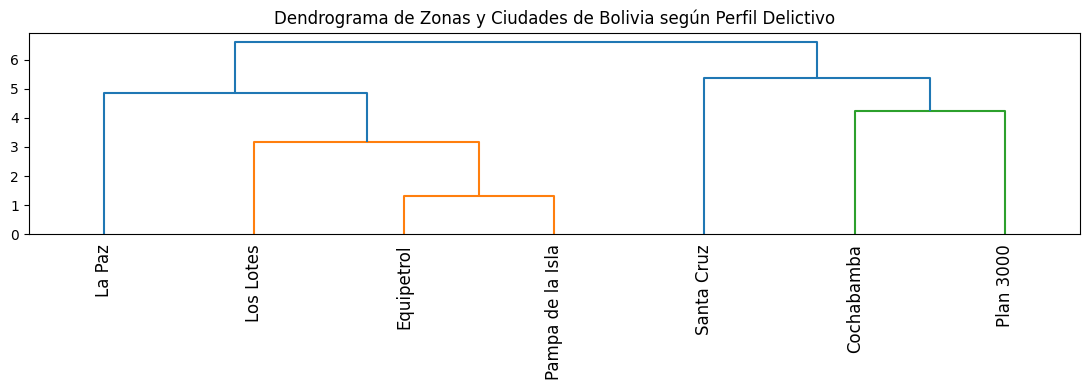

,n_hechos,indice_gravedad,pct_nocturno,lat,lon,pct_Agresión Física y Lesiones,pct_Homicidio / Asesinato,pct_Hurto / Descuidismo,pct_Narcotráfico / Drogas,pct_Robo Agravado / Asalto,pct_Violencia sexual,kmeans,jerarquico
zona_principal,,,,,,,,,,,,,
Santa Cruz,16,40,0.125000,-17.7833,-63.1821,0.125000,0.000000,0.250000,0.00,0.625000,0.000000,0,2
Cochabamba,9,30,0.444444,-17.3935,-66.1570,0.444444,0.111111,0.000000,0.00,0.333333,0.111111,2,1
Plan 3000,4,14,0.250000,-17.8285,-63.1415,0.250000,0.250000,0.000000,0.00,0.500000,0.000000,2,1
Equipetrol,3,9,0.000000,-17.7650,-63.1950,0.333333,0.000000,0.000000,0.00,0.666667,0.000000,1,0
La Paz,4,8,0.000000,-16.4958,-68.1336,0.500000,0.000000,0.250000,0.25,0.000000,0.000000,1,0
Los Lotes,3,7,0.000000,-17.8450,-63.1680,0.333333,0.000000,0.333333,0.00,0.333333,0.000000,1,0
Pampa de la Isla,2,6,0.000000,-17.7660,-63.1250,0.500000,0.000000,0.000000,0.00,0.500000,0.000000,1,0


In [18]:
if ZONAS_OK:
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    from sklearn.cluster import KMeans, AgglomerativeClustering
    from sklearn.metrics import silhouette_score
    from scipy.cluster.hierarchy import linkage, dendrogram
    import matplotlib.pyplot as plt

    PESO = {"Homicidio / Asesinato": 5, "Violencia sexual": 4, "Agresión Física y Lesiones": 3, "Robo Agravado / Asalto": 3,
            "Robo de Vehículos y Autopartes": 2, "Hurto / Descuidismo": 1, "Estafa y Engaño": 1, "Narcotráfico / Drogas": 1}

    def tabla_zonas(df, min_eventos=1):
        d = df.dropna(subset=["zona_principal"]).copy()
        d["peso"] = d["delito_principal"].map(PESO).fillna(1)
        T = d.groupby("zona_principal").agg(
            n_hechos=("url", "size"),
            indice_gravedad=("peso", "sum"),
            pct_nocturno=("franja", lambda s: s.isin(["Noche", "Madrugada"]).mean()),
            lat=("lat", "first"),
            lon=("lon", "first")
        )
        T = T.join(pd.crosstab(d["zona_principal"], d["delito_principal"], normalize="index").add_prefix("pct_"))
        return T[T.n_hechos >= min_eventos]

    TZ = tabla_zonas(df, min_eventos=2)
    if len(TZ) < 4:
        TZ = tabla_zonas(df, min_eventos=1)  # Si hay pocas zonas con >=2 eventos, incluye todas para poder graficar
    print("Zonas/Ciudades analizadas:", len(TZ))
    cols = [c for c in TZ.columns if c not in ("lat", "lon")]
    Z = StandardScaler().fit_transform(TZ[cols])
    pca = PCA(n_components=min(5, Z.shape[1], Z.shape[0] - 1)).fit(Z); Zp = pca.transform(Z)
    print("Varianza explicada PCA:", pca.explained_variance_ratio_.round(2))

    ks = range(2, min(8, len(TZ)))
    sil = {k: silhouette_score(Zp, KMeans(k, n_init=10, random_state=0).fit_predict(Zp)) for k in ks}
    k_opt = max(sil, key=sil.get); print("Silhouette por k:", {k: round(v, 3) for k, v in sil.items()}, "-> k =", k_opt)
    TZ["kmeans"] = KMeans(k_opt, n_init=10, random_state=0).fit_predict(Zp)
    TZ["jerarquico"] = AgglomerativeClustering(k_opt, linkage="ward").fit_predict(Zp)
    plt.figure(figsize=(11, 4))
    dendrogram(linkage(Zp, "ward"), labels=TZ.index.tolist(), leaf_rotation=90)
    plt.title("Dendrograma de Zonas y Ciudades de Bolivia según Perfil Delictivo")
    plt.tight_layout(); plt.show()
    display(TZ.sort_values("indice_gravedad", ascending=False))
else:
    print("Sección omitida: faltan eventos georreferenciados.")

# **Celda 19: 10.3 Texto: LDA, SVD, t-SNE y UMAP sobre las Noticias de Bolivia**

Tema 0: delincuentes, hecho, victima, arma, robo, mientras, antisociales, camaras, identificar, seguridad
Tema 1: vehiculo, mochila, madre, vida, hecho, tres, victima, camaras, lugar, momento
Tema 2: investigacion, sur, penal, fiscal, caso, abogado, personas, judicial, mientras, autoridades
Tema 3: vecinos, victima, hecho, robo, mayor, relato, lugar, mujer, mientras, presencia
Tema 4: victimas, familia, vehiculo, justicia, vecinos, saucedo, estado, motocicleta, tiene, vida


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


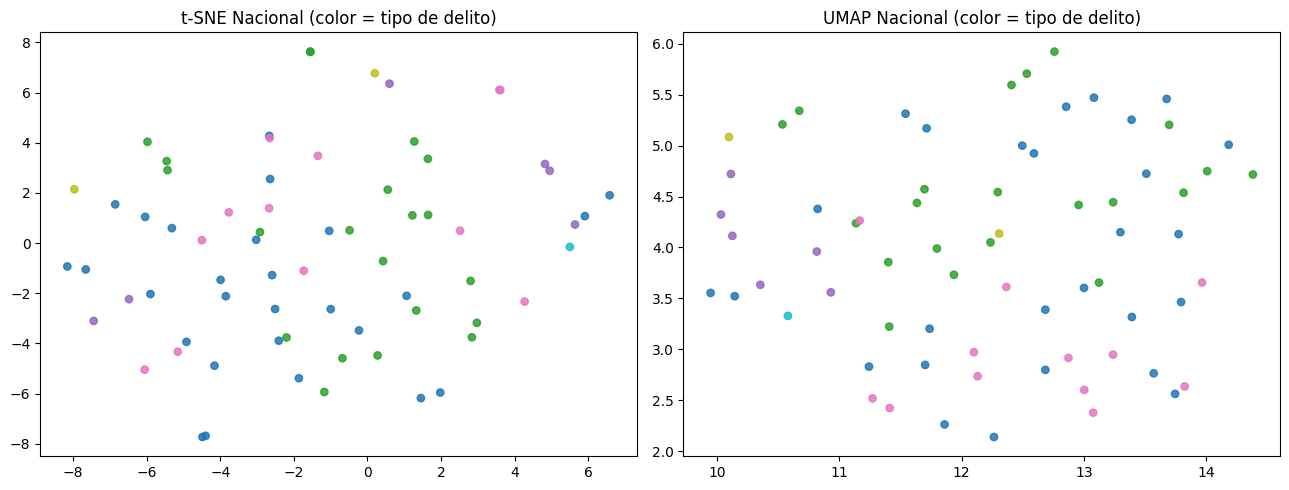

In [19]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import umap

STOP_ES = set("""a al algo ante asi aun aunque bajo cada como con contra cual cuando de del desde donde dos el ella ellos en entre era eran es esa ese eso esta estaba estan este esto estos fue fueron ha habia han hasta hay la las le les lo los mas me mi muy ni no nos o otra otro para pero por porque que quien se sea segun ser si sin sobre son su sus tambien tras un una uno unos y ya
paz alto santa cruz cochabamba bolivia policia policial policias fue sido tras dijo indico informo senalo ayer hoy anos ano horas hora zona""".split())

def vectorizar(textos, tfidf=False):
    V = (TfidfVectorizer if tfidf else CountVectorizer)(strip_accents="unicode", lowercase=True, stop_words=list(STOP_ES), max_df=0.85, min_df=2, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
    return V.fit_transform(textos), V

dfc = df_ciudad.copy().reset_index(drop=True)
Xc, Vc = vectorizar(dfc["texto"]); n_temas = 5
lda = LatentDirichletAllocation(n_components=n_temas, random_state=0, learning_method="batch").fit(Xc)
vocab = np.array(Vc.get_feature_names_out())
for t, comp in enumerate(lda.components_): print(f"Tema {t}:", ", ".join(vocab[comp.argsort()[-10:][::-1]]))
dfc["tema_lda"] = lda.transform(Xc).argmax(axis=1)

Xt, Vt = vectorizar(dfc["texto"], tfidf=True)
Xs = TruncatedSVD(n_components=min(30, Xt.shape[1] - 1, Xt.shape[0] - 1), random_state=0).fit_transform(Xt)
tsne = TSNE(2, perplexity=max(3, min(30, len(dfc) // 3)), random_state=0, init="pca").fit_transform(Xs)
um = umap.UMAP(n_components=2, n_neighbors=max(2, min(15, len(dfc) - 1)), random_state=0).fit_transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, E, nom in zip(ax, [tsne, um], ["t-SNE", "UMAP"]):
    scatter = a.scatter(E[:, 0], E[:, 1], c=pd.factorize(dfc["delito_principal"])[0], cmap="tab10", s=28, alpha=0.85)
    a.set_title(nom + " Nacional (color = tipo de delito)")
plt.tight_layout(); plt.show()

# **Celda 20: 10.4 Modelos Avanzados (PPCA y Autoencoders) + Exportación para Dashboard**

In [20]:
from sklearn.decomposition import FactorAnalysis
from sklearn.neural_network import MLPRegressor

# 1. PPCA (Probabilistic PCA mediante FactorAnalysis)
X_dense = Xt.toarray()
ppca = FactorAnalysis(n_components=2, random_state=0)
coords_ppca = ppca.fit_transform(X_dense)
dfc["ppca_x"], dfc["ppca_y"] = coords_ppca[:, 0], coords_ppca[:, 1]

# 2. Autoencoder (Red Neuronal cuello de botella: D -> 16 -> 2 -> 16 -> D) para detección de anomalías
ae = MLPRegressor(hidden_layer_sizes=(16, 2, 16), activation="relu", max_iter=300, random_state=0)
ae.fit(X_dense, X_dense)
reconstruccion = ae.predict(X_dense)
dfc["error_autoencoder"] = np.mean((X_dense - reconstruccion) ** 2, axis=1)

# Los eventos con mayor error de reconstrucción son crímenes atípicos / anomalías
umbral_anomalia = np.percentile(dfc["error_autoencoder"], 90)
dfc["es_anomalia"] = dfc["error_autoencoder"] >= umbral_anomalia
print(f"PPCA y Autoencoder entrenados. Anomalías detectadas (top 10%): {dfc['es_anomalia'].sum()} eventos.")
display(dfc[dfc["es_anomalia"]][["ciudad", "zona_principal", "delito_principal", "titulo", "error_autoencoder"]].head(5))

# 3. Exportación de resultados para el Dashboard
if ZONAS_OK:
    esp.to_csv("dashboard_eventos_clusters_bolivia.csv", index=False, encoding="utf-8")
    TZ.to_csv("dashboard_zonas_perfiles_bolivia.csv", encoding="utf-8")
dfc.to_csv("dashboard_texto_nlp_bolivia.csv", index=False, encoding="utf-8")
print("Archivos CSV exportados para el dashboard.")

PPCA y Autoencoder entrenados. Anomalías detectadas (top 10%): 7 eventos.


,ciudad,zona_principal,delito_principal,titulo,error_autoencoder
19,Santa Cruz,Plan 3000,Robo Agravado / Asalto,Delincuente en motocicleta asalta a una mujer ...,0.001154
24,Santa Cruz,Santa Cruz,Hurto / Descuidismo,"""Entraron como si fuera su casa"": Cámaras regi...",0.001202
25,La Paz,La Paz,Agresión Física y Lesiones,Soria debuta con victoria: Always Ready vence ...,0.001154
26,La Paz,La Paz,Narcotráfico / Drogas,"¿Quién es Williams Bascopé, el nuevo ministro ...",0.001158
45,La Paz,Pampahasi,Hurto / Descuidismo,Policía aprehende a trabajador de surtidor que...,0.001162


Archivos CSV exportados para el dashboard.
